In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")
def save_figure(filename):

    plt.tight_layout()

    plt.savefig(
        FIGURE_DIR / filename,
        dpi=300,
        bbox_inches="tight"
    )

    plt.close()

data_dir = Path(r"C:\Users\Parmidaa\vsprojects\statistics-project\data\raw\alzheimer")

uds = pd.read_csv(data_dir / "udslong_imputed.csv")
mri = pd.read_csv(data_dir / "mriscanclean.csv")

print("UDS shape:", uds.shape)
print("MRI shape:", mri.shape)

display(uds.head())
display(mri.head())
print("=" * 60)
print("UDS — udslong_imputed.csv")
print("=" * 60)
print("rows                 :", len(uds))
print("unique NACCID        :", uds["NACCID"].nunique())
print("repeated-id rows     :", uds["NACCID"].duplicated().sum())
print("is NACCID unique?    :", uds["NACCID"].is_unique)
print("dtype                :", uds["NACCID"].dtype)

visits_per_person = uds.groupby("NACCID").size()
print("\nvisits per participant:")
print(visits_per_person.describe())
print("\nhow many participants have 1, 2, 3, ... visits:")
print(visits_per_person.value_counts().sort_index())

print("\n" + "=" * 60)
print("MRI — mriscanclean.csv")
print("=" * 60)
print("rows                 :", len(mri))
print("unique NACCID        :", mri["NACCID"].nunique())
print("repeated-id rows     :", mri["NACCID"].duplicated().sum())
print("is NACCID unique?    :", mri["NACCID"].is_unique)
print("dtype                :", mri["NACCID"].dtype)

print("\n" + "=" * 60)
print("OVERLAP between files")
print("=" * 60)
uds_ids = set(uds["NACCID"])
mri_ids = set(mri["NACCID"])

print("UDS participants            :", len(uds_ids))
print("MRI participants            :", len(mri_ids))
print("matched participants        :", len(uds_ids & mri_ids))
print("UDS only (no MRI)           :", len(uds_ids - mri_ids))
print("MRI only (no UDS)           :", len(mri_ids - uds_ids))

# dtypes must match for a clean merge
if uds["NACCID"].dtype != mri["NACCID"].dtype:
    print("\n⚠️  WARNING: NACCID dtypes differ between files — cast both to str before merging.")
else:
    print("\n✓ NACCID dtypes match — safe to merge on this key.")

UDS shape: (1237, 180)
MRI shape: (1237, 126)


,NACCID,SEX,HISPANIC,HISPOR,RACE,PRIMLANG,EDUC,MARISTAT,NACCLIVS,INDEPEND,...,NACCAPOE,NACCUDSD,MEMORY,ORIENT,JUDGMENT,COMMUN,HOMEHOBB,PERSCARE,CDRSUM,CDRGLOB
0,NACC359836,1.0,0.0,88.0,1.0,1.0,18.0,1.0,2.0,1.0,...,4.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,NACC990210,2.0,0.0,88.0,1.0,1.0,16.0,1.0,2.0,1.0,...,1.0,1.0,0.5,0.0,0.0,0.0,0.0,0.0,0.5,0.5
2,NACC074744,1.0,0.0,88.0,1.0,1.0,20.0,1.0,2.0,1.0,...,9.0,3.0,1.0,0.5,0.5,0.5,0.5,0.0,3.0,0.5
3,NACC083525,1.0,0.0,88.0,1.0,1.0,16.0,1.0,2.0,1.0,...,9.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,NACC092141,2.0,0.0,88.0,1.0,1.0,14.0,1.0,2.0,1.0,...,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


,NACCID,LH_CAUDALANTERIORCINGULATE_GVOL,RH_CAUDALANTERIORCINGULATE_GVOL,LH_CAUDALANTERIORCINGULATE_AVGTH,RH_CAUDALANTERIORCINGULATE_AVGTH,LH_CAUDALMIDDLEFRONTAL_GVOL,RH_CAUDALMIDDLEFRONTAL_GVOL,LH_CAUDALMIDDLEFRONTAL_AVGTH,RH_CAUDALMIDDLEFRONTAL_AVGTH,LH_CUNEUS_GVOL,...,RH_SUPRAMARGINAL_AVGTH,LH_TRANSVERSETEMPORAL_GVOL,RH_TRANSVERSETEMPORAL_GVOL,LH_TRANSVERSETEMPORAL_AVGTH,RH_TRANSVERSETEMPORAL_AVGTH,LH_INSULA_GVOL,RH_INSULA_GVOL,LH_INSULA_AVGTH,RH_INSULA_AVGTH,NACCUDSD
0,NACC359836,3462,2257,2.328,2.278,6767,5857,2.274,2.303,5726,...,2.330,1028,786,2.060,2.075,5785,6224,3.045,3.129,1
1,NACC990210,3131,2528,2.553,2.292,6898,6880,2.478,2.415,4512,...,2.383,1430,783,2.193,2.479,6075,6200,2.999,2.846,1
2,NACC074744,2463,1618,2.060,1.942,7176,5770,2.254,2.268,4240,...,2.158,1299,1036,2.204,2.202,5912,6344,2.655,2.847,3
3,NACC083525,2980,2302,2.405,2.230,6915,6303,2.620,2.618,4790,...,2.599,1061,846,2.445,2.551,6226,6050,3.117,3.026,1
4,NACC092141,3000,1703,2.404,2.140,6655,6556,2.454,2.406,4075,...,2.427,1263,784,2.543,2.591,5582,5743,3.089,2.853,1


UDS — udslong_imputed.csv
rows                 : 1237
unique NACCID        : 1237
repeated-id rows     : 0
is NACCID unique?    : True
dtype                : str

visits per participant:
count    1237.0
mean        1.0
std         0.0
min         1.0
25%         1.0
50%         1.0
75%         1.0
max         1.0
dtype: float64

how many participants have 1, 2, 3, ... visits:
1    1237
Name: count, dtype: int64

MRI — mriscanclean.csv
rows                 : 1237
unique NACCID        : 1237
repeated-id rows     : 0
is NACCID unique?    : True
dtype                : str

OVERLAP between files
UDS participants            : 1237
MRI participants            : 1237
matched participants        : 1237
UDS only (no MRI)           : 0
MRI only (no UDS)           : 0

✓ NACCID dtypes match — safe to merge on this key.


In [3]:
# Basic information about the dataset
print("Dataset shape:", df.shape)

# Summary statistics for age
display(df["age"].describe())

# Frequency table for group
display(df["group"].value_counts())

Dataset shape: (10, 2)


count    10.000000
mean     33.600000
std       6.769211
min      25.000000
25%      28.250000
50%      33.000000
75%      38.500000
max      45.000000
Name: age, dtype: float64

group
A    5
B    5
Name: count, dtype: int64

In [ ]:
 
SENTINELS = [8, 9, 88, 99, 888, 8888, 999, 9999]

def sentinel_audit(df, name, sentinels=SENTINELS):
   """برای هر ستون عددی تعداد کدهای ویژه ."""
    rows = []
    for col in df.select_dtypes(include="number").columns:
        vals = df[col].dropna()
        counts = {f"n_{s}": int((vals == s).sum()) for s in sentinels}
        total_sentinel = sum(counts.values())
        if total_sentinel > 0:
            rows.append({
                "file": name,
                "column": col,
                "n_nonnull": len(vals),
                "n_sentinel": total_sentinel,
                "pct_sentinel": round(100 * total_sentinel / len(vals), 2),
                **counts,
            })
    return pd.DataFrame(rows).sort_values("n_sentinel", ascending=False)

uds_sent = sentinel_audit(uds, "UDS")
mri_sent = sentinel_audit(mri, "MRI")

print("=== UDS: ستون‌هایی که کد ویژه دارند ===")
print(uds_sent.head(40).to_string(index=False))

print("\n=== MRI: ستون‌هایی که کد ویژه دارند ===")
print(mri_sent.head(40).to_string(index=False))

=== UDS: ستون‌هایی که کد ویژه دارند ===
file   column  n_nonnull  n_sentinel  pct_sentinel  n_8  n_9  n_88  n_99  n_888  n_8888  n_999  n_9999
 UDS  NACCOMS       1237        1237        100.00    0 1237     0     0      0       0      0       0
 UDS  NACCFMS       1237        1236         99.92    0 1236     0     0      0       0      0       0
 UDS  HALLSEV       1237        1223         98.87 1223    0     0     0      0       0      0       0
 UDS  NACCAMS       1237        1207         97.57    1 1206     0     0      0       0      0       0
 UDS  ELATSEV       1237        1203         97.25 1203    0     0     0      0       0      0       0
 UDS   DELSEV       1237        1200         97.01 1200    0     0     0      0       0      0       0
 UDS   MOTSEV       1237        1181         95.47 1181    0     0     0      0       0      0       0
 UDS   HISPOR       1237        1161         93.86    0    0  1160     1      0       0      0       0
 UDS  DISNSEV       1237        1

In [20]:


# متغیرهای طبقه‌ای
categorical_vars = ["SEX", "NACCUDSD","CDRSUM"]

for var in categorical_vars:
    frequency = uds[var].value_counts(dropna=False).sort_index()

    table = pd.DataFrame({
        "Frequency": frequency,
        "Percentage (%)": (frequency / len(uds) * 100).round(2)
    })

    print(f"\nFrequency table for {var}")
    print(table)


Frequency table for SEX
     Frequency  Percentage (%)
SEX                           
1.0        497           40.18
2.0        740           59.82

Frequency table for NACCUDSD
          Frequency  Percentage (%)
NACCUDSD                           
1.0             847           68.47
2.0               7            0.57
3.0             252           20.37
4.0             131           10.59

Frequency table for CDRSUM
        Frequency  Percentage (%)
CDRSUM                           
0.0           757           61.20
0.5           144           11.64
1.0            97            7.84
1.5            50            4.04
2.0            39            3.15
2.5            35            2.83
3.0            20            1.62
3.5            12            0.97
4.0            14            1.13
4.5            21            1.70
5.0            10            0.81
5.5             3            0.24
6.0             9            0.73
6.5             1            0.08
7.0             5            0.40

              N   Mean    SD  Minimum    Q1  Median    Q3  Maximum
NACCAGE  1237.0  68.19  8.04     41.0  63.0    68.0  74.0     91.0
EDUC     1237.0  16.39  4.29      0.0  14.0    16.0  18.0     99.0
NACCGDS  1237.0   2.01  5.90      0.0   0.0     1.0   2.0     88.0
CDRSUM   1237.0   0.82  1.72      0.0   0.0     0.0   1.0     15.0


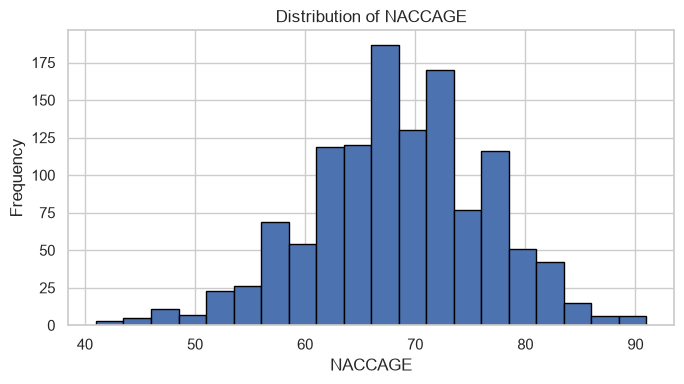

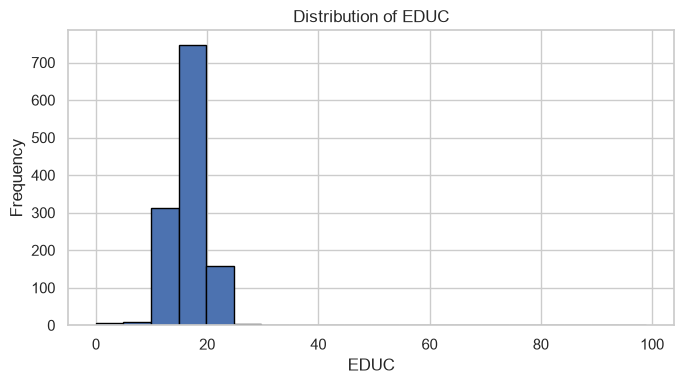

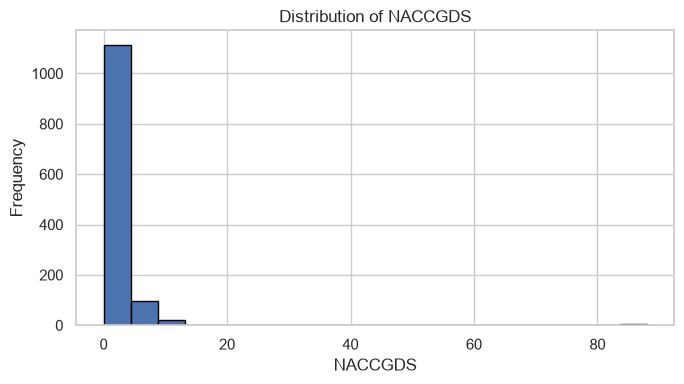

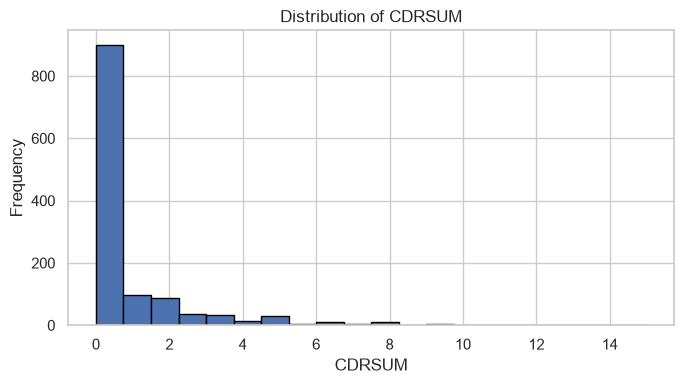

                          N     Mean      SD  Minimum       Q1   Median  \
LH_ENTORHINAL_GVOL   1237.0  1554.28  413.52     0.00  1295.00  1545.00   
LH_ENTORHINAL_AVGTH  1237.0     2.97    0.38     0.88     2.76     3.02   

                          Q3  Maximum  
LH_ENTORHINAL_GVOL   1785.00  4265.00  
LH_ENTORHINAL_AVGTH     3.23     3.98  


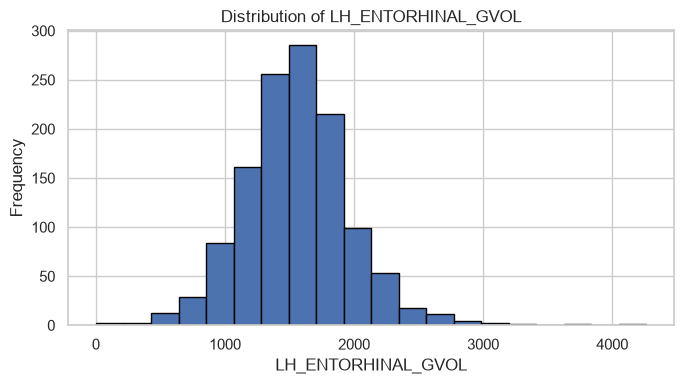

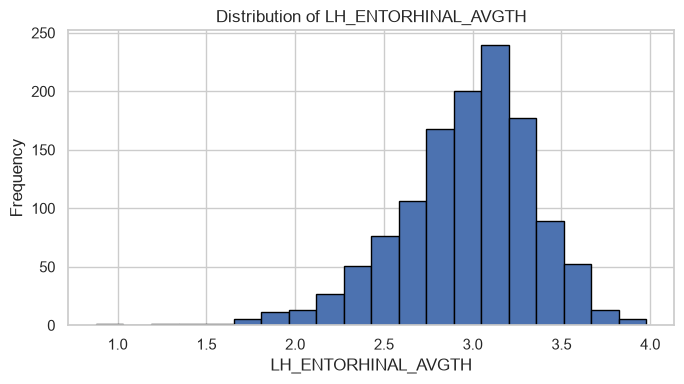

In [21]:
numeric_vars = ["NACCAGE", "EDUC", "NACCGDS", "CDRSUM"]

numeric_summary = uds[numeric_vars].describe().T

numeric_summary = numeric_summary[
    ["count", "mean", "std", "min", "25%", "50%", "75%", "max"]
].round(2)

numeric_summary = numeric_summary.rename(columns={
    "count": "N",
    "mean": "Mean",
    "std": "SD",
    "min": "Minimum",
    "25%": "Q1",
    "50%": "Median",
    "75%": "Q3",
    "max": "Maximum"
})

print(numeric_summary)

for var in numeric_vars:
    plt.figure(figsize=(7, 4))
    plt.hist(uds[var].dropna(), bins=20, edgecolor="black")
    plt.xlabel(var)
    plt.ylabel("Frequency")
    plt.title(f"Distribution of {var}")
    plt.tight_layout()
    plt.show()
mri_vars = [
    "LH_ENTORHINAL_GVOL",
    "LH_ENTORHINAL_AVGTH"
]

mri_summary = mri[mri_vars].describe().T

mri_summary = mri_summary[
    ["count", "mean", "std", "min", "25%", "50%", "75%", "max"]
].round(2)

mri_summary = mri_summary.rename(columns={
    "count": "N",
    "mean": "Mean",
    "std": "SD",
    "min": "Minimum",
    "25%": "Q1",
    "50%": "Median",
    "75%": "Q3",
    "max": "Maximum"
})

print(mri_summary)
for var in mri_vars:
    plt.figure(figsize=(7, 4))
    plt.hist(mri[var].dropna(), bins=20, edgecolor="black")
    plt.xlabel(var)
    plt.ylabel("Frequency")
    plt.title(f"Distribution of {var}")
    plt.tight_layout()
    plt.show()

In [22]:
def describe_quant(df, col, dataset_name):
    """Print Mean, SD, Min, Q1, Median, Q3, Max, IQR for a quantitative variable."""
    if col not in df.columns:
        print(f"[{dataset_name}] Variable '{col}' NOT FOUND.")
        return
    s = pd.to_numeric(df[col], errors='coerce').dropna()
    # Treat 888 / 888.8 / 999 as missing if they appear as codes
    s = s[~s.isin([888, 888.8, 999])]
    if len(s) == 0:
        print(f"[{dataset_name}] {col}: all values missing.")
        return
    q1, med, q3 = s.quantile([0.25, 0.5, 0.75])
    print(f"\n--- {col} ({dataset_name}) ---")
    print(f"  N        = {len(s)}")
    print(f"  Mean     = {s.mean():.2f}")
    print(f"  SD       = {s.std():.2f}")
    print(f"  Min      = {s.min():.2f}")
    print(f"  Q1       = {q1:.2f}")
    print(f"  Median   = {med:.2f}")
    print(f"  Q3       = {q3:.2f}")
    print(f"  Max      = {s.max():.2f}")
    print(f"  IQR      = {q3 - q1:.2f}")
    print(f"  Range    = {s.max() - s.min():.2f}")

def freq_table(df, col, dataset_name, top_n=None):
    """Print Frequency + Percentage table for a categorical variable."""
    if col not in df.columns:
        print(f"[{dataset_name}] Variable '{col}' NOT FOUND.")
        return
    s = df[col].dropna()
    counts = s.value_counts().sort_index()
    pcts = (counts / counts.sum() * 100).round(2)
    table = pd.DataFrame({'Frequency': counts, 'Percentage (%)': pcts})
    if top_n:
        table = table.head(top_n)
    print(f"\n--- Frequency table for {col} ({dataset_name}) ---")
    print(table)

# ---------------------------------------------------------
# 3. Quantitative variables (Mean, SD, Median, IQR, etc.)
# ---------------------------------------------------------
print("="*60)
print("QUANTITATIVE VARIABLES")
print("="*60)

# From mriscanclean.csv
describe_quant(mri, 'LH_PARAHIPPOCAMPAL_GVOL', 'mriscanclean')
describe_quant(mri, 'RH_PARAHIPPOCAMPAL_GVOL', 'mriscanclean')
describe_quant(mri, 'LH_PRECUNEUS_GVOL',       'mriscanclean')
describe_quant(mri, 'RH_PRECUNEUS_GVOL',       'mriscanclean')

# From udslong_imputed.csv
describe_quant(uds, 'NACCBMI',  'udslong_imputed')
describe_quant(uds, 'MOCATOTS', 'udslong_imputed')
describe_quant(uds, 'NACCAAAS', 'udslong_imputed')

# ---------------------------------------------------------
# 4. Categorical variables (Frequency & Percentage)
# ---------------------------------------------------------
print("\n" + "="*60)
print("CATEGORICAL VARIABLES")
print("="*60)

# From udslong_imputed.csv
freq_table(uds, 'CDRGLOB',  'udslong_imputed')
freq_table(uds, 'NACCAPOE', 'udslong_imputed')
freq_table(uds, 'HYPERTEN', 'udslong_imputed')
freq_table(uds, 'DIABETES', 'udslong_imputed')

QUANTITATIVE VARIABLES

--- LH_PARAHIPPOCAMPAL_GVOL (mriscanclean) ---
  N        = 1237
  Mean     = 2036.71
  SD       = 387.89
  Min      = 167.00
  Q1       = 1791.00
  Median   = 2019.00
  Q3       = 2257.00
  Max      = 5136.00
  IQR      = 466.00
  Range    = 4969.00

--- RH_PARAHIPPOCAMPAL_GVOL (mriscanclean) ---
  N        = 1237
  Mean     = 1911.24
  SD       = 344.96
  Min      = 74.00
  Q1       = 1718.00
  Median   = 1903.00
  Q3       = 2090.00
  Max      = 6335.00
  IQR      = 372.00
  Range    = 6261.00

--- LH_PRECUNEUS_GVOL (mriscanclean) ---
  N        = 1237
  Mean     = 8495.68
  SD       = 1416.19
  Min      = 124.00
  Q1       = 7698.00
  Median   = 8521.00
  Q3       = 9336.00
  Max      = 12914.00
  IQR      = 1638.00
  Range    = 12790.00

--- RH_PRECUNEUS_GVOL (mriscanclean) ---
  N        = 1237
  Mean     = 9267.06
  SD       = 1540.45
  Min      = 716.00
  Q1       = 8374.00
  Median   = 9228.00
  Q3       = 10192.00
  Max      = 14351.00
  IQR      = 181

In [6]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


plt.figure(figsize=(8,5))
plt.hist(uds['NACCAGE'].dropna(), bins=20, edgecolor='black', color='steelblue')
plt.xlabel('سن (سال)')
plt.ylabel('فراوانی')
plt.title('توزیع فراوانی سن شرکت‌کنندگان (NACCAGE)')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('hist_naccage.png', dpi=150)
plt.close()

# ۲. نمودار جعبه‌ای MoCA بر حسب CDR
df_box = uds[['MOCATOTS', 'CDRGLOB']].dropna()
df_box = df_box[df_box['MOCATOTS'] <= 30]  # حذف کد خطای ۸۸
plt.figure(figsize=(8,5))
sns.boxplot(x='CDRGLOB', y='MOCATOTS', data=df_box, color='steelblue')
plt.xlabel('گروه CDR')
plt.ylabel('نمره MoCA')
plt.title('مقایسه نمره MoCA در گروه‌های CDR')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('boxplot_moca_cdr.png', dpi=150)
plt.close()

# ۳. نمودار میله‌ای وضعیت شناختی
counts = uds['NACCUDSD'].value_counts().sort_index()
plt.figure(figsize=(8,5))
plt.bar(counts.index.astype(str), counts.values, color='steelblue', edgecolor='black')
plt.xlabel('گروه وضعیت شناختی (NACCUDSD)')
plt.ylabel('فراوانی')
plt.title('توزیع فراوانی وضعیت شناختی (NACCUDSD)')
plt.grid(alpha=0.3, axis='y')
plt.tight_layout()
plt.savefig('bar_naccudsd.png', dpi=150)
plt.close()

# ۴. نمودار پراکندگی حجم و ضخامت آنتورینال
df_sc = mri[['LH_ENTORHINAL_GVOL', 'LH_ENTORHINAL_AVGTH']].dropna()
plt.figure(figsize=(8,5))
plt.scatter(df_sc['LH_ENTORHINAL_GVOL'], df_sc['LH_ENTORHINAL_AVGTH'],
            alpha=0.4, color='steelblue', s=15)
plt.xlabel('حجم ناحیه آنتورینال چپ (mm³)')
plt.ylabel('ضخامت ناحیه آنتورینال چپ (mm)')
plt.title('رابطه حجم و ضخامت ناحیه آنتورینال چپ')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('scatter_entorhinal.png', dpi=150)
plt.close()


In [7]:
import pandas as pd



def group_stats(df, value_col, group_col, drop_codes=None):
    d = df[[value_col, group_col]].dropna()
    if drop_codes:
        d = d[~d[value_col].isin(drop_codes)]
    return d.groupby(group_col)[value_col].agg(
        N='count', Mean='mean', Median='median',
        SD='std',
        Q1=lambda x: x.quantile(0.25),
        Q3=lambda x: x.quantile(0.75)
    ).round(2)

# ۱. MoCA بر حسب NACCUDSD
print("=== MOCATOTS by NACCUDSD ===")
print(group_stats(uds, 'MOCATOTS', 'NACCUDSD', drop_codes=[88]))

# ۲. سن بر حسب SEX
print("\n=== NACCAGE by SEX ===")
print(group_stats(uds, 'NACCAGE', 'SEX'))

# ۳. حجم آنتورینال بر حسب CDRGLOB
merged = mri.merge(uds[['NACCID', 'CDRGLOB']], on='NACCID', how='inner')
print("\n=== LH_ENTORHINAL_GVOL by CDRGLOB ===")
print(group_stats(merged, 'LH_ENTORHINAL_GVOL', 'CDRGLOB'))

=== MOCATOTS by NACCUDSD ===
            N   Mean  Median    SD    Q1    Q3
NACCUDSD                                      
1.0       846  26.23    26.2  2.49  25.0  28.0
2.0         7  26.26    26.8  2.66  25.8  27.7
3.0       252  22.45    23.0  3.45  20.0  25.0
4.0       128  16.48    17.0  6.10  13.0  21.0

=== NACCAGE by SEX ===
       N   Mean  Median    SD    Q1    Q3
SEX                                      
1.0  497  68.99    70.0  7.74  64.0  74.0
2.0  740  67.66    68.0  8.20  63.0  73.0

=== LH_ENTORHINAL_GVOL by CDRGLOB ===
           N     Mean  Median      SD       Q1       Q3
CDRGLOB                                                
0.0      800  1601.26  1580.0  375.90  1376.75  1821.25
0.5      368  1476.72  1449.5  461.17  1173.25  1716.50
1.0       60  1430.85  1313.0  502.59  1103.50  1729.25
2.0        9  1371.44  1383.0  197.32  1266.00  1482.00


In [9]:
import pandas as pd

# تعداد شرکت‌کنندگان یکتا
n_unique = uds['NACCID'].nunique()
n_rows = len(uds)
print(f"تعداد شرکت‌کنندگان یکتا: {n_unique}")
print(f"تعداد رکوردها (مراجعه‌ها): {n_rows}")

# توزیع تعداد مراجعه به ازای هر شرکت‌کننده
visits_per_subject = uds['NACCID'].value_counts()
print("\nتوزیع تعداد مراجعه:")
print(visits_per_subject.value_counts().sort_index())

# آیا داده طولی است یا مقطعی؟
if n_unique == n_rows:
    print("\nنتیجه: داده مقطعی است (یک مشاهده به ازای هر نفر).")
else:
    print("\nنتیجه: داده طولی است (چند مشاهده به ازای هر نفر).")

تعداد شرکت‌کنندگان یکتا: 1237
تعداد رکوردها (مراجعه‌ها): 1237

توزیع تعداد مراجعه:
count
1    1237
Name: count, dtype: int64

نتیجه: داده مقطعی است (یک مشاهده به ازای هر نفر).


In [11]:
import pandas as pd

set_uds = set(uds['NACCID'])
set_mri = set(mri['NACCID'])
common = set_uds & set_mri
only_uds = set_uds - set_mri
only_mri = set_mri - set_uds

print(f"تعداد افراد در UDS: {len(set_uds)}")
print(f"تعداد افراد در MRI: {len(set_mri)}")
print(f"تعداد افراد مشترک: {len(common)}")
print(f"موارد فقط در UDS (بدون MRI): {len(only_uds)}")
print(f"موارد فقط در MRI (بدون UDS): {len(only_mri)}")

# حجم نمونه نهایی چندوجهی
merged = uds.merge(mri, on='NACCID', how='inner')
print(f"حجم نمونه نهایی چندوجهی: {len(merged)}")

تعداد افراد در UDS: 1237
تعداد افراد در MRI: 1237
تعداد افراد مشترک: 1237
موارد فقط در UDS (بدون MRI): 0
موارد فقط در MRI (بدون UDS): 0
حجم نمونه نهایی چندوجهی: 1237


In [12]:
import pandas as pd
import numpy as np

# درصد گمشدگی متغیرهای اصلی UDS (با در نظر گرفتن کدهای 888/999 به عنوان گمشده)
main_uds_vars = ['NACCAGE','EDUC','CDRGLOB','CDRSUM','MOCATOTS','NACCAPOE','NACCBMI','NACCAAAS','NACCGDS']
missing_codes = [888, 888.8, 999, 9]

print("درصد گمشدگی متغیرهای اصلی UDS:")
for var in main_uds_vars:
    if var in uds.columns:
        s = uds[var]
        # کدهای 9 فقط برای APOE و برخی متغیرهای اسمی معنی گمشده دارد
        if var in ['NACCAPOE']:
            n_missing = s.isin([9]).sum()
        elif var in ['NACCBMI','NACCAAAS']:
            n_missing = s.isin(missing_codes).sum()
        else:
            n_missing = s.isna().sum() + s.isin([888, 888.8, 999]).sum()
        pct = n_missing / len(s) * 100
        print(f"  {var}: {n_missing} ({pct:.2f}%)")

# مقایسه توصیفی افراد دارای MRI با کل نمونه UDS
merged = uds.merge(mri[['NACCID']], on='NACCID', how='inner')
uds['has_mri'] = uds['NACCID'].isin(mri['NACCID'])

for var in ['NACCAGE','EDUC','CDRGLOB']:
    print(f"\n{var}:")
    print(uds.groupby('has_mri')[var].agg(['count','mean','median','std']).round(2))

درصد گمشدگی متغیرهای اصلی UDS:
  NACCAGE: 0 (0.00%)
  EDUC: 0 (0.00%)
  CDRGLOB: 0 (0.00%)
  CDRSUM: 0 (0.00%)
  MOCATOTS: 0 (0.00%)
  NACCAPOE: 278 (22.47%)
  NACCBMI: 126 (10.19%)
  NACCAAAS: 0 (0.00%)
  NACCGDS: 0 (0.00%)

NACCAGE:
         count   mean  median   std
has_mri                            
True      1237  68.19    68.0  8.04

EDUC:
         count   mean  median   std
has_mri                            
True      1237  16.39    16.0  4.29

CDRGLOB:
         count  mean  median   std
has_mri                           
True      1237  0.21     0.0  0.33


C:\Users\Parmidaa\AppData\Local\Temp\ipykernel_6460\596898795.py:24: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  uds['has_mri'] = uds['NACCID'].isin(mri['NACCID'])


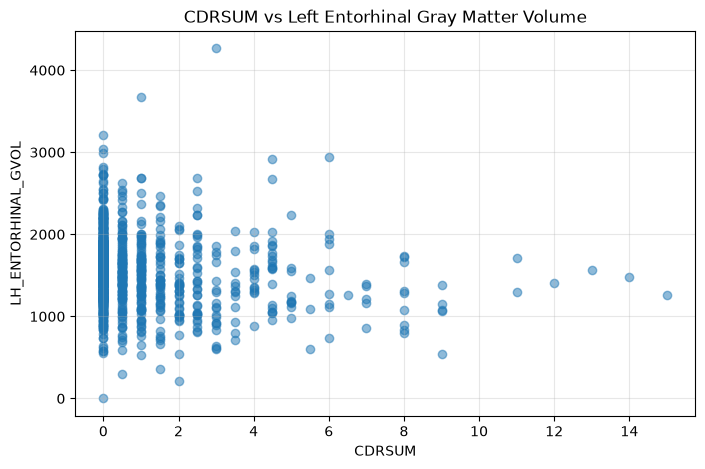

In [12]:
plt.figure(figsize=(8, 5))

plt.scatter(
    merged["CDRSUM"],
    merged["LH_ENTORHINAL_GVOL"],
    alpha=0.5
)

plt.xlabel("CDRSUM")
plt.ylabel("LH_ENTORHINAL_GVOL")
plt.title("CDRSUM vs Left Entorhinal Gray Matter Volume")

plt.grid(alpha=0.3)
plt.show()